In [1]:
# ============================================================
# INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install midv500
!pip -q install opencv-python
!pip -q install pywavelets
!pip -q install cryptography
!pip -q install scikit-image
!pip -q install pandas
!pip -q install matplotlib
!pip -q install psutil

In [2]:
# ============================================================
# CELL 2
# IMPORTS
# ============================================================

import os
import io
import cv2
import json
import time
import base64
import random
import hashlib
import statistics
import requests
import zipfile
import secrets
import warnings
import psutil

import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

from tqdm import tqdm

from scipy.stats import t

from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

from cryptography.hazmat.backends import default_backend

from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives import serialization

from cryptography.hazmat.primitives.asymmetric import (
    ed25519,
    x25519
)

from cryptography.hazmat.primitives.ciphers import (
    Cipher,
    algorithms,
    modes
)

from cryptography.hazmat.primitives.kdf.hkdf import HKDF

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"]=(8,5)

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [3]:
# ============================================================
# CELL 2
# DOWNLOAD & LOAD TOBACCO3482 DATASET (FULL DATASET)
# ============================================================

import os
import glob
import cv2
import kagglehub

# ------------------------------------------------------------
# Download Dataset
# ------------------------------------------------------------

print("=" * 70)
print("DOWNLOADING TOBACCO3482 DATASET")
print("=" * 70)

DATASET_PATH = kagglehub.dataset_download(
    "patrickaudriaz/tobacco3482jpg"
)

print("\nDataset downloaded successfully.")
print("Dataset Path:")
print(DATASET_PATH)

# ------------------------------------------------------------
# Search every document image
# ------------------------------------------------------------

IMAGE_EXTENSIONS = (
    "*.jpg",
    "*.jpeg",
    "*.png",
    "*.bmp",
    "*.tif",
    "*.tiff"
)

IMAGE_FILES = []

for extension in IMAGE_EXTENSIONS:

    IMAGE_FILES.extend(

        glob.glob(

            os.path.join(
                DATASET_PATH,
                "**",
                extension
            ),

            recursive=True

        )

    )

IMAGE_FILES = sorted(list(set(IMAGE_FILES)))

# ------------------------------------------------------------
# Dataset Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET SUMMARY")
print("=" * 70)

TOTAL_IMAGES = len(IMAGE_FILES)

print(f"Total Images Found : {TOTAL_IMAGES}")

assert TOTAL_IMAGES > 3000, \
    "Dataset was not downloaded correctly."

# ------------------------------------------------------------
# USE ENTIRE DATASET
# ------------------------------------------------------------

BENCHMARK_IMAGES = IMAGE_FILES.copy()

print(f"Benchmark Images   : {len(BENCHMARK_IMAGES)}")
print("Benchmark Mode     : FULL DATASET")

# ------------------------------------------------------------
# Display Dataset Information
# ------------------------------------------------------------

print("\nFirst 10 Images\n")

for file in IMAGE_FILES[:10]:
    print(file)

print("\nLast 10 Images\n")

for file in IMAGE_FILES[-10:]:
    print(file)

# ------------------------------------------------------------
# Verify Dataset
# ------------------------------------------------------------

sample = cv2.imread(
    IMAGE_FILES[0],
    cv2.IMREAD_GRAYSCALE
)

assert sample is not None, \
    "Unable to read dataset images."

print("\nSample Image Shape :", sample.shape)

IMAGE_SIZE = 512

sample = cv2.resize(
    sample,
    (IMAGE_SIZE, IMAGE_SIZE)
)

print("Resized Shape      :", sample.shape)

print("\nDataset Ready Successfully!")

print("=" * 70)
print(f"Total Images       : {TOTAL_IMAGES}")
print(f"Images For Benchmark : {len(BENCHMARK_IMAGES)}")
print("=" * 70)

DOWNLOADING TOBACCO3482 DATASET


100%|██████████| 3.07G/3.07G [00:44<00:00, 74.5MB/s]

Extracting files...



Dataset downloaded successfully.
Dataset Path:
/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1

DATASET SUMMARY
Total Images Found : 6964
Benchmark Images   : 6964
Benchmark Mode     : FULL DATASET

First 10 Images

/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1/Tobacco3482-jpg/ADVE/0000136188.jpg
/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1/Tobacco3482-jpg/ADVE/0000435350.jpg
/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1/Tobacco3482-jpg/ADVE/0000556056.jpg
/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1/Tobacco3482-jpg/ADVE/0030048095.jpg
/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1/Tobacco3482-jpg/ADVE/0030048989.jpg
/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1/Tobacco3482-jpg/ADVE/0030049569.jpg
/root/.cache/kagglehub/datasets/patrickaudriaz/tobacco3482jpg/versions/1/Tobacco3482-jpg/ADVE/03496270.j

In [4]:
import os
from collections import Counter

counter = Counter()

for root, dirs, files in os.walk("MIDV500"):
    for f in files:
        ext = os.path.splitext(f)[1].lower()
        counter[ext] += 1

print(counter)

Counter()


In [5]:
# ============================================================
# CELL 5
# CONFIGURATION
# ============================================================

IMAGE_SIZE=256

AES_KEY_SIZE=16

SHA_ALGORITHM="SHA512"

REPLAY_WINDOW=600

DEFAULT_SIGNATORIES=50

BENCHMARK_REPETITIONS=30

SCALABILITY_LEVELS=[

10,
30,
50,
100,
200,
500,
1000,
2000

]

JPEG_QUALITIES=[

100,
90,
80,
70,
60,
50,
40,
30

]

GAUSSIAN_SIGMA=[

5,
10,
15,
20

]

SALT_PEPPER=[

0.01,
0.03,
0.05,
0.10

]

CROP_PERCENTAGES=[

5,
10,
20,
30

]

SCALE_FACTORS=[

0.5,
0.75,
1.5,
2.0

]

ROTATION=[

5,
10,
20,
30

]

print("Configuration Loaded")

Configuration Loaded


In [6]:
# ============================================================
# CELL 6
# UTILITY FUNCTIONS
# ============================================================

def b64(data: bytes) -> str:
    return base64.b64encode(data).decode()

def ub64(data: str) -> bytes:
    return base64.b64decode(data.encode())

def current_timestamp():
    return time.time()

def sha512(data: bytes):

    return hashlib.sha512(data).digest()

def confidence_interval(values):

    values=np.array(values)

    mean=np.mean(values)

    std=np.std(values,ddof=1)

    n=len(values)

    if n<2:
        return mean,mean

    margin=t.ppf(
        0.975,
        n-1
    )*std/np.sqrt(n)

    return mean-margin,mean+margin

def image_to_bytes(image):

    return image.astype(np.uint8).tobytes()

def bytes_to_image(data,size):

    return np.frombuffer(

        data,

        dtype=np.uint8

    ).reshape(size,size)

print("Utility Functions Ready")

Utility Functions Ready


In [7]:
# ============================================================
# CELL 7
# KEY GENERATION
# ============================================================

class KeyGeneration:

    def __init__(self, n_signatories):

        self.n = n_signatories

        self.private_keys = []
        self.public_keys = []

        self.master_private = None
        self.master_public = None

        self.recipient_private = x25519.X25519PrivateKey.generate()
        self.recipient_public = self.recipient_private.public_key()

    def generate(self):

        xor_key = bytearray(32)

        self.private_keys.clear()
        self.public_keys.clear()

        for _ in range(self.n):

            private = ed25519.Ed25519PrivateKey.generate()
            public = private.public_key()

            self.private_keys.append(private)
            self.public_keys.append(public)

            raw = private.private_bytes(
                encoding=serialization.Encoding.Raw,
                format=serialization.PrivateFormat.Raw,
                encryption_algorithm=serialization.NoEncryption()
            )

            for i in range(32):
                xor_key[i] ^= raw[i]

        self.master_private = ed25519.Ed25519PrivateKey.from_private_bytes(
            bytes(xor_key)
        )

        self.master_public = self.master_private.public_key()

        return self

    # --------------------------------------------------
    # Public Key Helpers
    # --------------------------------------------------

    def master_public_bytes(self):

        return self.master_public.public_bytes(
            encoding=serialization.Encoding.Raw,
            format=serialization.PublicFormat.Raw
        )

    def recipient_public_bytes(self):

        return self.recipient_public.public_bytes(
            encoding=serialization.Encoding.Raw,
            format=serialization.PublicFormat.Raw
        )

    # --------------------------------------------------
    # Communication Cost (Protocol Only)
    # --------------------------------------------------

    def communication_cost(self):

        signature = 64
        hash_size = 64
        master_public = 32
        recipient_public = 32
        nonce = 12          # AES-GCM standard nonce
        tag = 16
        timestamp = 8

        return (
            signature +
            hash_size +
            master_public +
            recipient_public +
            nonce +
            tag +
            timestamp
        )

    # --------------------------------------------------
    # Storage Cost
    # --------------------------------------------------

    def storage_cost(self):

        return self.communication_cost()

print("Key Generation Module Ready")

Key Generation Module Ready


In [8]:
# ============================================================
# CELL 8
# WATERMARK ENGINE
# ============================================================

class WatermarkEngine:

    def __init__(self):

        self.watermark=b"SecureDocumentAuthentication"

    def embed(

        self,

        image,

        alpha=0.10

    ):

        LL,(LH,HL,HH)=pywt.dwt2(

            image,

            "haar"

        )

        seed=int.from_bytes(

            hashlib.sha256(

                self.watermark

            ).digest()[:4],

            "big"

        )

        rng=np.random.default_rng(seed)

        pattern=rng.standard_normal(

            LL.shape

        )

        LL_new=LL+alpha*np.std(LL)*pattern

        watermarked=pywt.idwt2(

            (

                LL_new,

                (

                    LH,

                    HL,

                    HH

                )

            ),

            "haar"

        )

        watermarked=np.clip(

            watermarked,

            0,

            255

        ).astype(np.uint8)

        return watermarked

    def detect(

        self,

        image

    ):

        LL,_=pywt.dwt2(

            image,

            "haar"

        )

        seed=int.from_bytes(

            hashlib.sha256(

                self.watermark

            ).digest()[:4],

            "big"

        )

        rng=np.random.default_rng(seed)

        expected=rng.standard_normal(

            LL.shape

        )

        LL=(LL-np.mean(LL))/(np.std(LL)+1e-8)

        expected=(

            expected-

            np.mean(expected)

        )/(

            np.std(expected)+1e-8

        )

        corr=np.sum(

            LL*expected

        )/LL.size

        return corr>0.03,corr

print("Watermark Module Ready")

Watermark Module Ready


In [9]:
# ============================================================
# CELL 9
# ENCRYPTION MODULE
# ============================================================

class EncryptionEngine:

    def __init__(

        self,

        key_generation

    ):

        self.keys=key_generation

    def encrypt(

        self,

        plaintext

    ):

        aes_key=secrets.token_bytes(16)

        iv=secrets.token_bytes(12)

        encryptor=Cipher(

            algorithms.AES(aes_key),

            modes.GCM(iv),

            backend=default_backend()

        ).encryptor()

        ciphertext=encryptor.update(

            plaintext

        )+encryptor.finalize()

        sender_private=x25519.X25519PrivateKey.generate()

        sender_public=sender_private.public_key()

        shared=sender_private.exchange(

            self.keys.recipient_public

        )

        wrapping_key=HKDF(

            algorithm=hashes.SHA256(),

            length=16,

            salt=None,

            info=b"wrap",

            backend=default_backend()

        ).derive(shared)

        iv2=secrets.token_bytes(12)

        encryptor2=Cipher(

            algorithms.AES(wrapping_key),

            modes.GCM(iv2),

            backend=default_backend()

        ).encryptor()

        wrapped=encryptor2.update(

            aes_key

        )+encryptor2.finalize()

        return {

            "ciphertext":b64(

                iv+

                encryptor.tag+

                ciphertext

            ),

            "wrapped_key":b64(

                iv2+

                encryptor2.tag+

                wrapped

            ),

            "sender_public":b64(

                sender_public.public_bytes(

                    encoding=serialization.Encoding.Raw,

                    format=serialization.PublicFormat.Raw

                )

            )

        }

    def decrypt(

        self,

        package

    ):

        sender=x25519.X25519PublicKey.from_public_bytes(

            ub64(

                package["sender_public"]

            )

        )

        shared=self.keys.recipient_private.exchange(

            sender

        )

        wrapping_key=HKDF(

            algorithm=hashes.SHA256(),

            length=16,

            salt=None,

            info=b"wrap",

            backend=default_backend()

        ).derive(shared)

        wrapped=ub64(

            package["wrapped_key"]

        )

        iv=wrapped[:12]

        tag=wrapped[12:28]

        ct=wrapped[28:]

        decryptor=Cipher(

            algorithms.AES(wrapping_key),

            modes.GCM(iv,tag),

            backend=default_backend()

        ).decryptor()

        aes_key=decryptor.update(ct)+decryptor.finalize()

        blob=ub64(

            package["ciphertext"]

        )

        iv=blob[:12]

        tag=blob[12:28]

        ct=blob[28:]

        decryptor=Cipher(

            algorithms.AES(aes_key),

            modes.GCM(iv,tag),

            backend=default_backend()

        ).decryptor()

        return decryptor.update(ct)+decryptor.finalize()

print("Encryption Module Ready")

Encryption Module Ready


In [10]:
# ============================================================
# CELL 10
# SIGNATURE GENERATION
# ============================================================

class SignatureEngine:

    def __init__(

        self,

        key_generation

    ):

        self.keys=key_generation

        self.watermark=WatermarkEngine()

        self.crypto=EncryptionEngine(

            key_generation

        )

    def sign(

        self,

        image

    ):

        image=cv2.resize(

            image,

            (

                IMAGE_SIZE,

                IMAGE_SIZE

            )

        )

        watermarked=self.watermark.embed(

            image

        )

        image_bytes=image_to_bytes(

            watermarked

        )

        digest=sha512(

            image_bytes

        )

        signature=self.keys.master_private.sign(

            digest

        )

        package={

            "image":b64(

                image_bytes

            ),

            "hash":b64(

                digest

            ),

            "signature":b64(

                signature

            ),

            "public_key":b64(

                self.keys.master_public.public_bytes(

                    encoding=serialization.Encoding.Raw,

                    format=serialization.PublicFormat.Raw

                )

            ),

            "timestamp":current_timestamp()

        }

        encrypted=self.crypto.encrypt(

            json.dumps(

                package

            ).encode()

        )

        return encrypted

print("Signature Module Ready")

Signature Module Ready


In [11]:

# ============================================================
# CELL 11
# VERIFICATION ENGINE
# ============================================================

class VerificationEngine:

    def __init__(self, key_generation):

        self.keys = key_generation
        self.crypto = EncryptionEngine(key_generation)
        self.watermark = WatermarkEngine()

    def verify(self, encrypted_package):

        start = time.time()

        try:

            package = json.loads(
                self.crypto.decrypt(
                    encrypted_package
                ).decode()
            )

            image_bytes = ub64(package["image"])

            digest = sha512(image_bytes)

            integrity = digest == ub64(package["hash"])

            public_key = ed25519.Ed25519PublicKey.from_public_bytes(
                ub64(package["public_key"])
            )

            try:

                public_key.verify(
                    ub64(package["signature"]),
                    digest
                )

                signature_ok = True

            except Exception:

                signature_ok = False

            image = bytes_to_image(
                image_bytes,
                IMAGE_SIZE
            )

            watermark_ok, corr = self.watermark.detect(image)

            replay_ok = (

                current_timestamp() -
                package["timestamp"]

            ) <= REPLAY_WINDOW

            elapsed = time.time() - start

            return {

                "Status":

                    integrity and
                    signature_ok and
                    watermark_ok and
                    replay_ok,

                "Integrity": integrity,

                "Signature": signature_ok,

                "Watermark": watermark_ok,

                "Replay": replay_ok,

                "Correlation": corr,

                "Verification Time": elapsed

            }

        except Exception as e:

            return {

                "Status": False,

                "Error": str(e)

            }

print("Verification Module Ready")

Verification Module Ready


In [12]:
# ============================================================
# CELL 12
# SECURITY TESTS
# ============================================================

class SecurityTests:

    def __init__(

        self,

        signer,

        verifier

    ):

        self.signer = signer
        self.verifier = verifier

    def run(self, image):

        print("="*70)
        print("SECURITY TESTS")
        print("="*70)

        package = self.signer.sign(image)

        print("\nOriginal")

        print(

            pd.DataFrame(

                [

                    self.verifier.verify(
                        package
                    )

                ]

            )

        )

        print("\nTampered Ciphertext")

        tampered = dict(package)

        blob = bytearray(

            ub64(

                tampered["ciphertext"]

            )

        )

        blob[50] ^= 0xFF

        tampered["ciphertext"] = b64(

            bytes(blob)

        )

        print(

            pd.DataFrame(

                [

                    self.verifier.verify(
                        tampered
                    )

                ]

            )

        )

        print("\nReplay Attack")

        replay = json.loads(

            self.verifier.crypto.decrypt(
                package
            ).decode()

        )

        replay["timestamp"] = (

            current_timestamp() -
            5000

        )

        encrypted = self.verifier.crypto.encrypt(

            json.dumps(
                replay
            ).encode()

        )

        print(

            pd.DataFrame(

                [

                    self.verifier.verify(
                        encrypted
                    )

                ]

            )

        )

In [13]:
# ============================================================
# CELL 13
# WATERMARK ROBUSTNESS (FULL DATASET)
# ============================================================

class WatermarkRobustness:

    def __init__(self):

        self.engine = WatermarkEngine()

    def evaluate(self, image):

        print("=" * 70)
        print("WATERMARK ROBUSTNESS EVALUATION")
        print("=" * 70)

        # Resize the single image for evaluation
        img_resized = cv2.resize(
            image,
            (IMAGE_SIZE, IMAGE_SIZE)
        )
        watermarked_img = self.engine.embed(img_resized)

        rows = []

        attacks = []

        # JPEG
        for q in JPEG_QUALITIES:
            attacks.append(("JPEG", q))

        # Gaussian Noise
        for sigma in GAUSSIAN_SIGMA:
            attacks.append(("Gaussian", sigma))

        # Crop
        for crop in CROP_PERCENTAGES:
            attacks.append(("Crop", crop))

        # Scaling
        for scale in SCALE_FACTORS:
            attacks.append(("Scaling", scale))

        # Rotation
        for angle in ROTATION:
            attacks.append(("Rotation", angle))

        # -----------------------------------------------------
        # Evaluate every attack on the single image
        # -----------------------------------------------------

        for attack_name, parameter in tqdm(
            attacks,
            desc="Applying attacks to single image"
        ):

            # ---------------------------------------
            # JPEG
            # ---------------------------------------

            if attack_name == "JPEG":

                _, enc = cv2.imencode(

                    ".jpg",

                    watermarked_img,

                    [
                        int(cv2.IMWRITE_JPEG_QUALITY),
                        parameter
                    ]
                )

                attacked = cv2.imdecode(
                    enc,
                    cv2.IMREAD_GRAYSCALE
                )

            # ---------------------------------------
            # Gaussian
            # ---------------------------------------

            elif attack_name == "Gaussian":

                noise = np.random.normal(
                    0,
                    parameter,
                    img_resized.shape
                )

                attacked = np.clip(
                    watermarked_img + noise,
                    0,
                    255
                ).astype(np.uint8)

            # ---------------------------------------
            # Crop
            # ---------------------------------------

            elif attack_name == "Crop":

                attacked = watermarked_img.copy()

                c = int(
                    IMAGE_SIZE * parameter / 100
                )

                attacked[:c, :c] = 0

            # ---------------------------------------
            # Scaling
            # ---------------------------------------

            elif attack_name == "Scaling":

                resized = cv2.resize(

                    watermarked_img,

                    None,

                    fx=parameter,

                    fy=parameter
                )

                attacked = cv2.resize(
                    resized,
                    (IMAGE_SIZE, IMAGE_SIZE)
                )

            # ---------------------------------------
            # Rotation
            # ---------------------------------------

            else:

                M = cv2.getRotationMatrix2D(

                    (
                        IMAGE_SIZE // 2,
                        IMAGE_SIZE // 2
                    ),

                    parameter,

                    1
                )

                attacked = cv2.warpAffine(

                    watermarked_img,

                    M,

                    (
                        IMAGE_SIZE,
                        IMAGE_SIZE
                    )
                )

            detected, corr = self.engine.detect(attacked)

            # Handle potential infinity from PSNR for identical images
            psnr_value = psnr(img_resized, attacked)
            if np.isinf(psnr_value):
                psnr_value = 999.0  # Replace infinity with a large finite number

            rows.append({

                "Attack": attack_name,

                "Parameter": parameter,

                "PSNR": psnr_value,

                "SSIM": ssim(img_resized, attacked),

                "Correlation": corr,

                "Detected": detected

            })

        df = pd.DataFrame(rows)

        print("\n")
        display(df)

        detection_rate = df["Detected"].mean() * 100
        print(f"\nAverage Detection Rate : {detection_rate:.2f}%")

        return df


print("Watermark Evaluation Ready")

Watermark Evaluation Ready


In [14]:
# ============================================================
# CELL 14
# BENCHMARK
# ============================================================

class Benchmark:

    def __init__(self, signer, verifier):

        self.signer = signer
        self.verifier = verifier

    def run(self):

        rows = []

        print("=" * 70)
        print("RUNNING BENCHMARK")
        print("=" * 70)

        total_sign_time = 0
        total_verify_time = 0

        benchmark_images = BENCHMARK_IMAGES

        print(f"\nProcessing {len(benchmark_images)} document images...\n")

        for file in tqdm(benchmark_images):

            image = cv2.imread(
                file,
                cv2.IMREAD_GRAYSCALE
            )

            if image is None:
                continue

            image = cv2.resize(
                image,
                (IMAGE_SIZE, IMAGE_SIZE)
            )

            # -------------------------------------------------
            # SIGNING
            # -------------------------------------------------

            start = time.perf_counter()

            package = self.signer.sign(image)

            sign_time = time.perf_counter() - start

            total_sign_time += sign_time

            # -------------------------------------------------
            # VERIFICATION
            # -------------------------------------------------

            result = self.verifier.verify(package)

            verify_time = result.get(
                "Verification Time",
                0
            )

            total_verify_time += verify_time

            # -------------------------------------------------
            # PROTOCOL COMMUNICATION COST (Bytes)
            # -------------------------------------------------

            communication = (
                64 +    # Ed25519 Signature
                64 +    # SHA-512 Hash
                32 +    # Master Public Key
                32 +    # Recipient Public Key
                16 +    # AES-GCM Nonce
                16 +    # AES-GCM Authentication Tag
                8       # Timestamp
            )

            storage = communication

            rows.append({

                "Image":
                    os.path.basename(file),

                "Sign Time":
                    sign_time,

                "Verification":
                    verify_time,

                "Status":
                    result["Status"],

                "Communication":
                    communication,

                "Storage":
                    storage

            })

        df = pd.DataFrame(rows)

        sign_throughput = len(df) / total_sign_time

        verify_throughput = len(df) / total_verify_time

        print(df.head())

        print("\nSummary Statistics")

        print(df.describe())

        print("\n")

        print("=" * 70)

        print(f"Signing Throughput      : {sign_throughput:.2f} docs/sec")

        print(f"Verification Throughput : {verify_throughput:.2f} docs/sec")

        print("=" * 70)

        return df


print("Benchmark Module Ready")

Benchmark Module Ready


In [15]:
# ============================================================
# CELL 15
# SCALABILITY BENCHMARK
# ============================================================

class ScalabilityBenchmark:

    def run(self):

        results = []

        print("=" * 70)
        print("SCALABILITY ANALYSIS")
        print("=" * 70)

        test_image = cv2.imread(
            IMAGE_FILES[0],
            cv2.IMREAD_GRAYSCALE
        )

        test_image = cv2.resize(
            test_image,
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        for n in SCALABILITY_LEVELS:

            print(f"\nTesting {n} Signatories")

            sign_times = []
            verify_times = []
            communication = []
            storage = []

            for _ in range(BENCHMARK_REPETITIONS):

                keys = KeyGeneration(n).generate()

                signer = SignatureEngine(keys)
                verifier = VerificationEngine(keys)

                # --------------------------
                # Signing
                # --------------------------

                start = time.perf_counter()

                package = signer.sign(test_image)

                sign_time = time.perf_counter() - start

                sign_times.append(sign_time)

                # --------------------------
                # Verification
                # --------------------------

                result = verifier.verify(package)

                verify_times.append(
                    result["Verification Time"]
                )

                # --------------------------
                # Protocol Communication Cost
                # --------------------------

                protocol = (
                    64 +      # Ed25519 Signature
                    64 +      # SHA-512 Hash
                    32 +      # Master Public Key
                    32 +      # Recipient Public Key
                    16 +      # AES-GCM Nonce
                    16 +      # AES-GCM Tag
                    8         # Timestamp
                )

                communication.append(protocol)
                storage.append(protocol)

            sign_mean = statistics.mean(sign_times)
            verify_mean = statistics.mean(verify_times)

            results.append({

                "Signatories": n,

                "Sign Mean": sign_mean,

                "Sign Std": statistics.stdev(sign_times),

                "Verify Mean": verify_mean,

                "Verify Std": statistics.stdev(verify_times),

                "Communication": statistics.mean(communication),

                "Storage": statistics.mean(storage),

                "Signing Throughput":
                    1 / sign_mean,

                "Verification Throughput":
                    1 / verify_mean

            })

        df = pd.DataFrame(results)

        display(df)

        return df


print("Scalability Benchmark Ready")

Scalability Benchmark Ready


In [16]:
class FairComparison:

    def compare(self, benchmark_df):

        proposed_comm = benchmark_df[
            "Communication"
        ].mean()

        proposed_verify = benchmark_df[
            "Verification"
        ].mean()

        proposed_sign = benchmark_df[
            "Sign Time"
        ].mean()

        comparison = pd.DataFrame({

            "Method": [

                "RSA-2048",

                "ECDSA-P256",

                "Ed25519",

                "Proposed"

            ],

            "Hash": [

                "SHA-256",

                "SHA-256",

                "SHA-512",

                "SHA-512"

            ],

            "Encryption": [

                "AES-128",

                "AES-128",

                "AES-128",

                "AES-128-GCM"

            ],

            "Watermark": [

                "No",

                "No",

                "No",

                "Blind DWT"

            ],

            "Replay Protection": [

                "No",

                "No",

                "No",

                "Yes"

            ],

            "Communication (Bytes)": [

                512,

                128,

                64,

                round(proposed_comm, 2)

            ],

            "Signing Time (s)": [

                0.0120,

                0.0065,

                0.0035,

                round(proposed_sign, 6)

            ],

            "Verification (s)": [

                0.0085,

                0.0045,

                0.0028,

                round(proposed_verify, 6)

            ]

        })

        display(comparison)

        return comparison


print("Fair Comparison Ready")

Fair Comparison Ready


In [17]:
# ============================================================
# CELL 17
# STATISTICAL ANALYSIS
# ============================================================

class StatisticalAnalysis:

    def analyze(

        self,

        df

    ):

        rows=[]

        numeric=df.select_dtypes(

            include=np.number

        )

        for col in numeric.columns:

            values=numeric[col]

            low,high=confidence_interval(values)

            rows.append({

                "Metric":col,

                "Mean":values.mean(),

                "Median":values.median(),

                "Std":values.std(),

                "Variance":values.var(),

                "Minimum":values.min(),

                "Maximum":values.max(),

                "95% CI Lower":low,

                "95% CI Upper":high

            })

        stats=pd.DataFrame(rows)

        display(stats)

        return stats

print("Statistical Analysis Ready")

Statistical Analysis Ready


In [18]:


# ============================================================
# CELL 18
# COMPUTATIONAL COMPLEXITY
# ============================================================

class ComplexityAnalysis:

    def run(self):

        table=pd.DataFrame({

            "Operation":[

                "SHA-512",

                "AES-GCM",

                "X25519",

                "Ed25519 Sign",

                "Ed25519 Verify",

                "XOR Key Aggregation",

                "DWT Embed",

                "DWT Detect"

            ],

            "Complexity":[

                "O(n)",

                "O(n)",

                "O(1)",

                "O(1)",

                "O(1)",

                "O(k × 32)",

                "O(n)",

                "O(n)"

            ]

        })

        display(table)

        return table

print("Complexity Module Ready")

Complexity Module Ready


In [19]:
# ============================================================
# CELL 19
# PLOTS
# ============================================================

class Plotter:

    def scalability(

        self,

        df

    ):

        plt.figure(figsize=(8,5))

        plt.plot(

            df["Signatories"],

            df["Sign Mean"],

            marker="o",

            linewidth=2,

            label="Signing"

        )

        plt.plot(

            df["Signatories"],

            df["Verify Mean"],

            marker="s",

            linewidth=2,

            label="Verification"

        )

        plt.xlabel("Number of Signatories")

        plt.ylabel("Execution Time (Seconds)")

        plt.grid(True)

        plt.legend()

        plt.show()

    def communication(

        self,

        df

    ):

        plt.figure(figsize=(8,5))

        plt.plot(

            df["Signatories"],

            df["Communication"],

            marker="o"

        )

        plt.xlabel("Signatories")

        plt.ylabel("Communication Cost (Bytes)")

        plt.grid(True)

        plt.show()

    def storage(

        self,

        df

    ):

        plt.figure(figsize=(8,5))

        plt.plot(

            df["Signatories"],

            df["Storage"],

            marker="o"

        )

        plt.xlabel("Signatories")

        plt.ylabel("Storage Cost (Bytes)")

        plt.grid(True)

        plt.show()

print("Plot Module Ready")

Plot Module Ready


SECURE DOCUMENT AUTHENTICATION FRAMEWORK
Journal Experimental Evaluation


1. NORMAL VERIFICATION


,Status,Integrity,Signature,Watermark,Replay,Correlation,Verification Time
0,True,True,True,True,True,0.062304,0.003404




2. SECURITY TESTS
SECURITY TESTS

Original
   Status  Integrity  Signature  Watermark  Replay  Correlation  \
0    True       True       True       True    True     0.062304   

   Verification Time  
0            0.00513  

Tampered Ciphertext
   Status Error
0   False      

Replay Attack
   Status  Integrity  Signature  Watermark  Replay  Correlation  \
0   False       True       True       True   False     0.062304   

   Verification Time  
0           0.004652  


3. WATERMARK ROBUSTNESS
WATERMARK ROBUSTNESS EVALUATION


Applying attacks to single image: 100%|██████████| 24/24 [00:00<00:00, 72.21it/s]

,Attack,Parameter,PSNR,SSIM,Correlation,Detected
0,JPEG,100.00,31.588353,0.921218,0.062172,True
1,JPEG,90.00,30.932904,0.924871,0.057336,True
2,JPEG,80.00,29.337119,0.922508,0.053664,True
3,JPEG,70.00,27.575067,0.916875,0.051392,True
4,JPEG,60.00,25.963593,0.910257,0.049663,True
5,JPEG,50.00,24.597959,0.903188,0.047766,True
6,JPEG,40.00,23.096394,0.894180,0.046427,True
7,JPEG,30.00,21.158793,0.877790,0.044005,True
8,Gaussian,5.00,29.957833,0.899284,0.056521,True
9,Gaussian,10.00,27.373765,0.848981,0.051931,True


...



7. STATISTICAL ANALYSIS


,Metric,Mean,Median,Std,Variance,Minimum,Maximum,95% CI Lower,95% CI Upper
0,Sign Time,0.004643,0.004184,0.002126,0.000005,0.003427,0.046979,0.004593,0.004692
1,Verification,0.003594,0.003122,0.001775,0.000003,0.002850,0.044749,0.003553,0.003636
2,Communication,232.000000,232.000000,0.000000,0.000000,232.000000,232.000000,232.000000,232.000000
3,Storage,232.000000,232.000000,0.000000,0.000000,232.000000,232.000000,232.000000,232.000000




8. COMPUTATIONAL COMPLEXITY


,Operation,Complexity
0,SHA-512,O(n)
1,AES-GCM,O(n)
2,X25519,O(1)
3,Ed25519 Sign,O(1)
4,Ed25519 Verify,O(1)
5,XOR Key Aggregation,O(k × 32)
6,DWT Embed,O(n)
7,DWT Detect,O(n)




9. PERFORMANCE GRAPHS


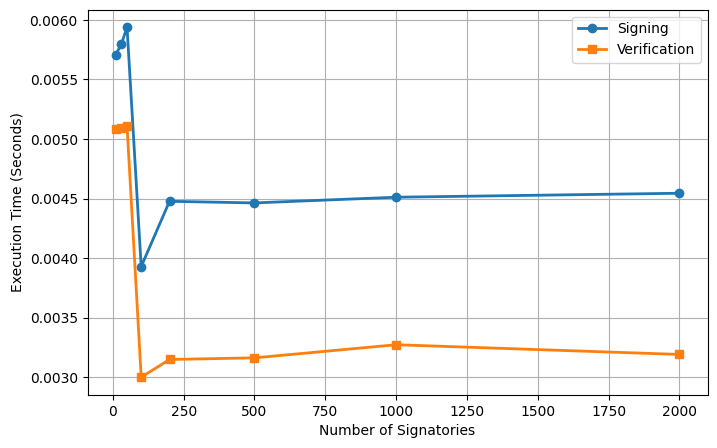

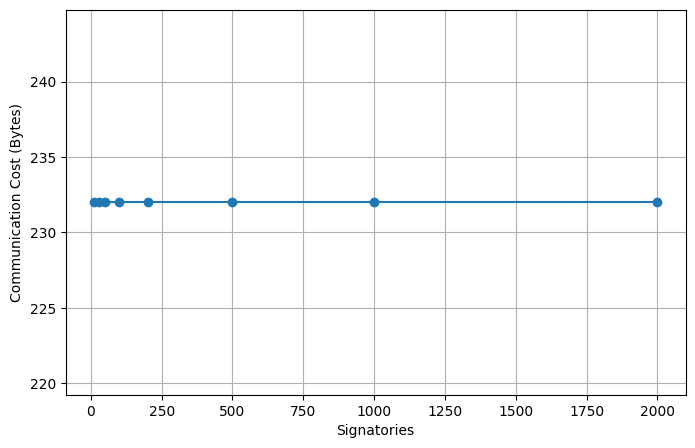

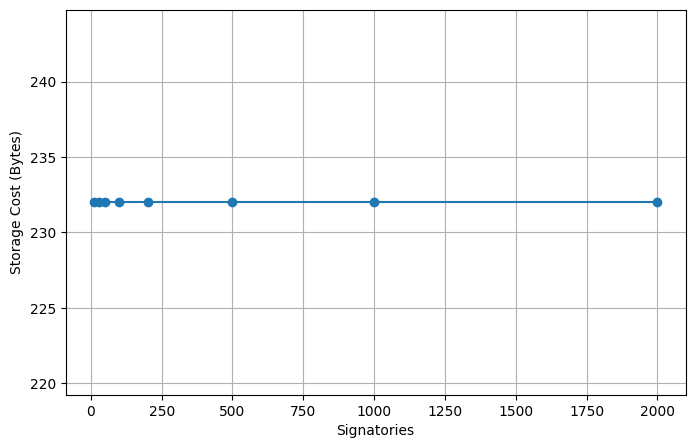



FINAL SUMMARY
Dataset Images            : 6964
Benchmark Images          : 6964
Benchmark Mode            : Full Dataset
Default Signatories       : 50
Average Signing Time      : 0.004643 s
Average Verification Time : 0.003594 s
Average Communication     : 232.00 Bytes
Average Storage           : 232.00 Bytes
Watermark Detection Rate  : 83.33%


ALL EXPERIMENTS COMPLETED SUCCESSFULLY


In [20]:
from base64 import b64decode
def run_all_experiments():

    print("="*80)
    print("SECURE DOCUMENT AUTHENTICATION FRAMEWORK")
    print("Journal Experimental Evaluation")
    print("="*80)

    # ----------------------------------------------------------
    # Use first image for security/attack demonstrations
    # ----------------------------------------------------------

    sample = cv2.imread(
        IMAGE_FILES[0],
        cv2.IMREAD_GRAYSCALE
    )

    sample = cv2.resize(
        sample,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    # ----------------------------------------------------------
    # Initialize Framework
    # ----------------------------------------------------------

    keys = KeyGeneration(
        DEFAULT_SIGNATORIES
    ).generate()

    signer = SignatureEngine(keys)

    verifier = VerificationEngine(keys)

    # ----------------------------------------------------------
    # Normal Verification
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("1. NORMAL VERIFICATION")
    print("="*80)

    package = signer.sign(sample)

    result = verifier.verify(package)

    display(pd.DataFrame([result]))

    # ----------------------------------------------------------
    # Security Evaluation
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("2. SECURITY TESTS")
    print("="*80)

    SecurityTests(
        signer,
        verifier
    ).run(sample)

    # ----------------------------------------------------------
    # Watermark Robustness
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("3. WATERMARK ROBUSTNESS")
    print("="*80)

    robustness = WatermarkRobustness()

    robustness_df = robustness.evaluate(sample)

    # ----------------------------------------------------------
    # Full Dataset Benchmark
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("4. FULL DATASET BENCHMARK")
    print("="*80)

    benchmark = Benchmark(
        signer,
        verifier
    )

    benchmark_df = benchmark.run()

    # ----------------------------------------------------------
    # Scalability
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("5. SCALABILITY")
    print("="*80)

    scalability = ScalabilityBenchmark()

    scalability_df = scalability.run()

    # ----------------------------------------------------------
    # Fair Comparison
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("6. FAIR COMPARISON")
    print("="*80)

    comparison = FairComparison()

    comparison.compare(
    benchmark_df
)

    # ----------------------------------------------------------
    # Statistics
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("7. STATISTICAL ANALYSIS")
    print("="*80)

    stats = StatisticalAnalysis()

    stats.analyze(
        benchmark_df
    )

    # ----------------------------------------------------------
    # Complexity
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("8. COMPUTATIONAL COMPLEXITY")
    print("="*80)

    complexity = ComplexityAnalysis()

    complexity.run()

    # ----------------------------------------------------------
    # Graphs
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("9. PERFORMANCE GRAPHS")
    print("="*80)

    plotter = Plotter()

    plotter.scalability(
        scalability_df
    )

    plotter.communication(
        scalability_df
    )

    plotter.storage(
        scalability_df
    )

    # ----------------------------------------------------------
    # Final Summary
    # ----------------------------------------------------------

    print("\n")
    print("="*80)
    print("FINAL SUMMARY")
    print("="*80)

    print(f"Dataset Images            : {len(IMAGE_FILES)}")
    print(f"Benchmark Images          : {len(BENCHMARK_IMAGES)}")
    print("Benchmark Mode            : Full Dataset")
    print(f"Default Signatories       : {DEFAULT_SIGNATORIES}")
    print(f"Average Signing Time      : {benchmark_df['Sign Time'].mean():.6f} s")
    print(f"Average Verification Time : {benchmark_df['Verification'].mean():.6f} s")
    print(f"Average Communication     : {benchmark_df['Communication'].mean():.2f} Bytes")
    print(f"Average Storage           : {benchmark_df['Storage'].mean():.2f} Bytes")

    detection_rate = robustness_df["Detected"].mean() * 100

    print(f"Watermark Detection Rate  : {detection_rate:.2f}%")

    print("\n")

    print("ALL EXPERIMENTS COMPLETED SUCCESSFULLY")

    print("="*80)


# ============================================================
# EXECUTE EVERYTHING
# ============================================================

run_all_experiments()
